# RIAWELC Weld Defect Pipeline
## Results, Model Comparison and Statistical Analysis

## 1. Environment Setup

### 1.1 Import Libraries

In [1]:
import os, json, warnings
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, roc_auc_score, roc_curve, cohen_kappa_score, matthews_corrcoef,
                             classification_report)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)

### 1.2 Configuration

In [2]:
PROJECT_DIR = Path(r"C:\Users\dipkh\Downloads\RIAWLC\3")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
OUTPUT_ROOT = PROJECT_DIR / "riawelc_outputs"
MODEL_ORDER  = ["ResNet50", "EfficientNet-B3", "ConvNeXt-Tiny"]
PROTOCOLS    = ["weld_holdout", "known_weld"]
PROTO_LABELS = {"weld_holdout": "Unseen welds (weld-disjoint)", "known_weld": "Known welds (official split, de-duplicated)"}
N_BOOTSTRAP, SEED = 1000, 42
RESULTS_DIR = OUTPUT_ROOT / "final_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load Predictions

In [3]:
runs = {}
for proto in PROTOCOLS:
    shared = OUTPUT_ROOT / proto / "_shared"
    if not (shared / "config.json").exists():
        continue
    cfg = json.loads((shared / "config.json").read_text())
    preds = {}
    for m in MODEL_ORDER:
        f = shared / "predictions" / f"{m}.npz"
        if f.exists():
            preds[m] = np.load(f, allow_pickle=True)
    if preds:
        ref = next(iter(preds.values()))["path"]
        assert all((v["path"] == ref).all() for v in preds.values()), f"Prediction order mismatch in {proto}"
        runs[proto] = dict(cfg=cfg, preds=preds, y=next(iter(preds.values()))["y"])
assert runs, "No predictions found. Run notebooks 00–03 first."
first = next(iter(runs.values()))["cfg"]
CLASS_ORDER = first["class_order"]
NAMES = [first["display_names"][k] for k in CLASS_ORDER]
SHORT = [first["short_names"][k] for k in CLASS_ORDER]
NUM_CLASSES = len(CLASS_ORDER)
ND = CLASS_ORDER.index("NoDifetto")
for p, r in runs.items():
    print(f"{PROTO_LABELS[p]}: models {list(r['preds'])} | test images {len(r['y']):,} | "
          f"YOLO mAP50 {r['cfg']['yolo_val_metrics']['mAP50']:.4f} ({r['cfg']['annotation']})")

Unseen welds (weld-disjoint): models ['ResNet50', 'EfficientNet-B3', 'ConvNeXt-Tiny'] | test images 4,682 | YOLO mAP50 0.7964 (automatic weak boxes)


## 3. Metric Functions

In [4]:
def compute_metrics(y, prob):
    pred = prob.argmax(1)
    P, R, F1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    try:
        auc = roc_auc_score(label_binarize(y, classes=range(NUM_CLASSES)), prob, average="macro")
    except ValueError:
        auc = np.nan
    yb, pb = (y != ND).astype(int), (pred != ND).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "Precision (macro)": P, "Recall (macro)": R, "F1 (macro)": F1,
            "Balanced acc.": balanced_accuracy_score(y, pred), "ROC-AUC (macro)": auc,
            "Cohen κ": cohen_kappa_score(y, pred), "MCC": matthews_corrcoef(y, pred),
            "Defect-vs-ND acc.": accuracy_score(yb, pb)}

def bootstrap_acc_ci(y, prob):
    rng = np.random.default_rng(SEED); pred = prob.argmax(1)
    s = [accuracy_score(y[i], pred[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(N_BOOTSTRAP))]
    return np.percentile(s, [2.5, 97.5])

for r in runs.values():
    if len(r["preds"]) >= 2:
        r["preds"] = {**r["preds"], "Ensemble": {"prob": np.mean([v["prob"] for v in r["preds"].values()], 0)}}

## 4. Overall Model Comparison

In [5]:
tables = {}
for proto, r in runs.items():
    rows = {}
    for m, v in r["preds"].items():
        met = compute_metrics(r["y"], v["prob"])
        lo, hi = bootstrap_acc_ci(r["y"], v["prob"])
        met["Accuracy 95% CI"] = f"[{lo:.4f}, {hi:.4f}]"
        rows[m] = met
    tables[proto] = pd.DataFrame(rows).T
    tables[proto].to_csv(RESULTS_DIR / f"comparison_{proto}.csv")
    print(f"\n{PROTO_LABELS[proto]}")
    display(tables[proto].drop(columns="Accuracy 95% CI").astype(float).round(4).join(tables[proto]["Accuracy 95% CI"]))


Unseen welds (weld-disjoint)


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Balanced acc.,ROC-AUC (macro),Cohen κ,MCC,Defect-vs-ND acc.,Accuracy 95% CI
ResNet50,0.7324,0.8124,0.8032,0.7573,0.8032,0.9318,0.6519,0.6968,0.9964,"[0.7204, 0.7441]"
EfficientNet-B3,0.7371,0.8141,0.7995,0.7630,0.7995,0.9283,0.6564,0.6962,0.9985,"[0.7249, 0.7493]"
ConvNeXt-Tiny,0.7616,0.8007,0.7986,0.7835,0.7986,0.9382,0.6823,0.6973,0.9955,"[0.7503, 0.7728]"
Ensemble,0.7452,0.8109,0.8052,0.7714,0.8052,0.9435,0.6659,0.6997,0.9972,"[0.7332, 0.7567]"


## 5. Per-Class Precision, Recall and F1

In [6]:
for proto, r in runs.items():
    blocks = []
    for m, v in r["preds"].items():
        rep = classification_report(r["y"], v["prob"].argmax(1), labels=range(NUM_CLASSES), target_names=SHORT,
                                    output_dict=True, zero_division=0)
        blocks.append(pd.DataFrame({c: [rep[c]["precision"], rep[c]["recall"], rep[c]["f1-score"]] for c in SHORT},
                                   index=pd.MultiIndex.from_product([[m], ["Precision", "Recall", "F1"]])))
    pc = pd.concat(blocks)
    pc.to_csv(RESULTS_DIR / f"per_class_{proto}.csv")
    print(f"\n{PROTO_LABELS[proto]}")
    display(pc.round(4))


Unseen welds (weld-disjoint)


LP      CR      PO      ND
ResNet50        Precision  0.4077  0.8687  0.9809  0.9924
                Recall     0.8917  0.3470  0.9809  0.9932
                F1         0.5596  0.4959  0.9809  0.9928
EfficientNet-B3 Precision  0.4101  0.8581  0.9917  0.9966
                Recall     0.8791  0.3867  0.9348  0.9975
                F1         0.5593  0.5332  0.9624  0.9970
ConvNeXt-Tiny   Precision  0.4274  0.7853  0.9918  0.9983
                Recall     0.7286  0.5291  0.9528  0.9839
                F1         0.5388  0.6322  0.9719  0.9910
Ensemble        Precision  0.4153  0.8343  0.9965  0.9974
                Recall     0.8472  0.4092  0.9730  0.9915
                F1         0.5574  0.5491  0.9847  0.9945

## 6. Confusion Matrices

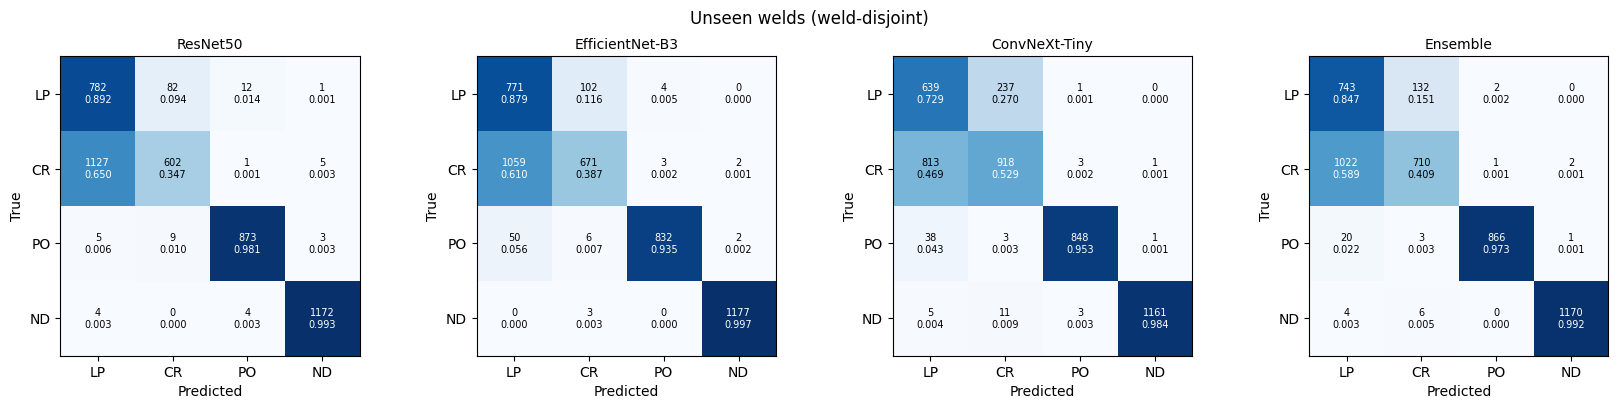

In [7]:
for proto, r in runs.items():
    ms = list(r["preds"])
    fig, axes = plt.subplots(1, len(ms), figsize=(4.2 * len(ms), 4), squeeze=False)
    for ax, m in zip(axes[0], ms):
        cm = confusion_matrix(r["y"], r["preds"][m]["prob"].argmax(1), labels=range(NUM_CLASSES))
        cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
        ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]:.3f}", ha="center", va="center", fontsize=7,
                        color="white" if cmn[i, j] > 0.5 else "black")
        ax.set_xticks(range(NUM_CLASSES), SHORT); ax.set_yticks(range(NUM_CLASSES), SHORT)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(m, fontsize=10)
    plt.suptitle(PROTO_LABELS[proto]); plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"confusion_matrices_{proto}.png", dpi=200); plt.show()

## 7. ROC Curves

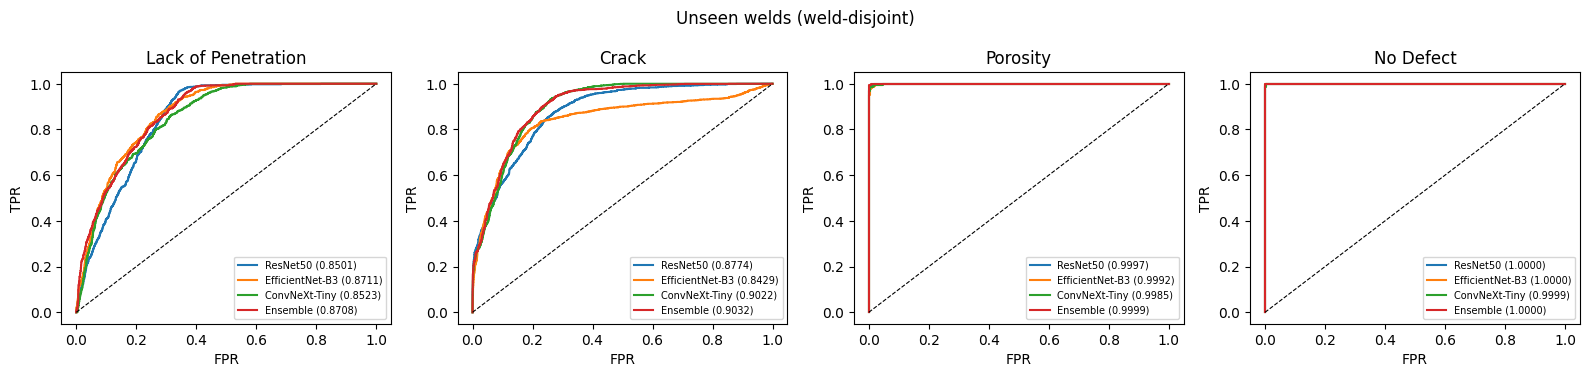

In [8]:
for proto, r in runs.items():
    yb = label_binarize(r["y"], classes=range(NUM_CLASSES))
    fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(4 * NUM_CLASSES, 3.8))
    for k, ax in enumerate(axes):
        for m, v in r["preds"].items():
            if 0 < yb[:, k].sum() < len(yb):
                fpr, tpr, _ = roc_curve(yb[:, k], v["prob"][:, k])
                ax.plot(fpr, tpr, label=f"{m} ({roc_auc_score(yb[:, k], v['prob'][:, k]):.4f})")
        ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_title(NAMES[k]); ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.legend(fontsize=7)
    plt.suptitle(PROTO_LABELS[proto]); plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"roc_curves_{proto}.png", dpi=200); plt.show()

## 8. Statistical Significance (McNemar Exact Test)

In [9]:
for proto, r in runs.items():
    rows = []
    for a, b in combinations(list(r["preds"]), 2):
        ca = r["preds"][a]["prob"].argmax(1) == r["y"]
        cb = r["preds"][b]["prob"].argmax(1) == r["y"]
        n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
        p = binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
        rows.append({"Model A": a, "Model B": b, "A right / B wrong": n01, "A wrong / B right": n10,
                     "p-value": round(p, 5), "Significant (α=0.05)": p < 0.05})
    mc = pd.DataFrame(rows)
    mc.to_csv(RESULTS_DIR / f"mcnemar_{proto}.csv", index=False)
    print(f"\n{PROTO_LABELS[proto]}")
    display(mc)


Unseen welds (weld-disjoint)


,Model A,Model B,A right / B wrong,A wrong / B right,p-value,Significant (α=0.05)
0,ResNet50,EfficientNet-B3,200,222,0.30665,False
1,ResNet50,ConvNeXt-Tiny,243,380,0.00000,True
2,ResNet50,Ensemble,107,167,0.00035,True
3,EfficientNet-B3,ConvNeXt-Tiny,242,357,0.00000,True
4,EfficientNet-B3,Ensemble,108,146,0.02007,True
5,ConvNeXt-Tiny,Ensemble,231,154,0.00010,True


## 9. Protocol Comparison: Known Welds vs Unseen Welds

In [10]:
if len(tables) == 2:
    comp = pd.DataFrame({PROTO_LABELS[p]: tables[p]["Accuracy"].astype(float) for p in PROTOCOLS}).round(4)
    comp["Generalisation gap"] = (comp.iloc[:, 1] - comp.iloc[:, 0]).round(4)
    comp.to_csv(RESULTS_DIR / "protocol_comparison.csv")
    display(comp)
    comp.iloc[:, :2].plot.bar(figsize=(8, 4), rot=0, ylim=(max(0, comp.iloc[:, :2].values.min() - 0.05), 1.0))
    plt.ylabel("Test accuracy"); plt.title("Accuracy by evaluation protocol"); plt.tight_layout()
    plt.savefig(RESULTS_DIR / "protocol_comparison.png", dpi=200); plt.show()
else:
    print("Run notebooks 00–03 with both PROTOCOL values to produce this comparison.")

Run notebooks 00–03 with both PROTOCOL values to produce this comparison.


## 10. Export Publication Tables

In [11]:
def to_latex(frame, caption, label):
    cols = list(frame.columns)
    lines = ["\\begin{table}[t]", "\\centering", f"\\caption{{{caption}}}", f"\\label{{{label}}}",
             "\\begin{tabular}{l" + "c" * len(cols) + "}", "\\hline", "Model & " + " & ".join(cols) + " \\\\", "\\hline"]
    for idx, row in frame.iterrows():
        lines.append(f"{idx} & " + " & ".join(f"{v:.4f}" if isinstance(v, (float, np.floating)) else str(v) for v in row) + " \\\\")
    lines += ["\\hline", "\\end{tabular}", "\\end{table}"]
    return "\n".join(lines)

keep = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "ROC-AUC (macro)", "MCC"]
for proto, t in tables.items():
    tex = to_latex(t[keep].astype(float), f"Test-set performance: {PROTO_LABELS[proto]}", f"tab:{proto}")
    (RESULTS_DIR / f"table_{proto}.tex").write_text(tex)
print("Exported to", RESULTS_DIR.resolve())
for f in sorted(RESULTS_DIR.iterdir()):
    print("  ", f.name)

Exported to C:\Users\dipkh\Downloads\RIAWLC\3\riawelc_outputs\final_results
   comparison_weld_holdout.csv
   confusion_matrices_weld_holdout.png
   mcnemar_weld_holdout.csv
   per_class_weld_holdout.csv
   roc_curves_weld_holdout.png
   table_weld_holdout.tex
